<a href="https://colab.research.google.com/github/gedeManik/klasifikasi_citra_sampah_sungai/blob/main/02_Final_Training_dan_Testing_MobileNetV2_YOLO11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Final Training & Final Testing — MobileNetV2 dan YOLO11n-cls
**Klasifikasi citra sampah sungai: anorganik dan organik**

Notebook ini menggabungkan final training dan final testing. Notebook membaca manifest split yang dibuat oleh Notebook 1 agar pembagian development 85% dan independent test 15% tetap sama.

Alur: final train/validation split dari development → training kedua model → evaluasi independent test → metrik Accuracy, Precision, Recall, F1-score, inference time, FPS, confusion matrix.

## 1. Persiapan dataset dan membaca manifest split

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip -q install -U ultralytics

import os, random, shutil, time, gc, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

SEED = 42
DATASET_DIR = Path('/content/drive/MyDrive/dataset')  # folder berisi subfolder kelas
WORK_DIR = Path('/content/drive/MyDrive/hasil_penelitian_sampah_sungai')
WORK_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 20
PATIENCE = 5
CLASS_NAMES = ['anorganik', 'organik']

random.seed(SEED)
np.random.seed(SEED)

assert DATASET_DIR.exists(), f"Folder dataset tidak ditemukan: {DATASET_DIR}"
for cls in CLASS_NAMES:
    assert (DATASET_DIR / cls).exists(), f"Subfolder kelas tidak ditemukan: {DATASET_DIR / cls}"

extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
records = []
for label, cls in enumerate(CLASS_NAMES):
    for p in sorted((DATASET_DIR / cls).rglob('*')):
        if p.is_file() and p.suffix.lower() in extensions:
            records.append({'path': str(p), 'label': label, 'class_name': cls})

df = pd.DataFrame(records)
assert len(df) > 0, "Tidak ada gambar ditemukan."
print("Jumlah gambar:", len(df))
print(df.groupby('class_name').size())

manifest_path = WORK_DIR / 'dataset_split_manifest.csv'
assert manifest_path.exists(), (
    f"Manifest tidak ditemukan: {manifest_path}. "
    "Jalankan Notebook 1 sampai bagian split dataset terlebih dahulu."
)

manifest = pd.read_csv(manifest_path)
dev_df = manifest[manifest['split'] == 'development'].copy()
test_df = manifest[manifest['split'] == 'test'].copy()

assert len(dev_df) > 0 and len(test_df) > 0
print("Development:", len(dev_df))
print("Independent test:", len(test_df))
print("Distribusi test:")
print(test_df['class_name'].value_counts())

# Split final: 90% train dan 10% validation dari development
train_df, val_df = train_test_split(
    dev_df,
    test_size=0.10,
    random_state=SEED,
    stratify=dev_df['label']
)

print("\\nFinal train:", len(train_df))
print("Final validation:", len(val_df))
print("Final test:", len(test_df))

X_train, y_train = train_df['path'].to_numpy(), train_df['label'].to_numpy()
X_val, y_val = val_df['path'].to_numpy(), val_df['label'].to_numpy()
X_test, y_test_true = test_df['path'].to_numpy(), test_df['label'].to_numpy()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Jumlah gambar: 306
class_name
anorganik    150
organik      156
dtype: int64
Development: 260
Independent test: 46
Distribusi test:
class_name
anorganik    23
organik      23
Name: count, dtype: int64
\nFinal train: 234
Final validation: 26
Final test: 46


## 2. Final Training MobileNetV2

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

def make_tf_dataset(paths, labels, training=False):
    paths = np.asarray(paths)
    labels = np.asarray(labels, dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.io.decode_image(image, channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
        image = tf.cast(image, tf.float32)
        return image, label

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

def build_mobilenet():
    augmentation = keras.Sequential([
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(0.04)
    ], name='online_augmentation')

    base = keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights='imagenet'
    )
    base.trainable = False

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = augmentation(inputs)
    x = keras.applications.mobilenet_v2.preprocess_input(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(2, activation='softmax')(x)
    model = keras.Model(inputs, outputs)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

train_ds = make_tf_dataset(X_train, y_train, training=True)
val_ds = make_tf_dataset(X_val, y_val, training=False)
test_ds = make_tf_dataset(X_test, y_test_true, training=False)

mobilenet_model = build_mobilenet()
mobilenet_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        mode='max',
        patience=PATIENCE,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(WORK_DIR / 'mobilenetv2_best.keras'),
        monitor='val_accuracy',
        mode='max',
        save_best_only=True
    ),
    keras.callbacks.CSVLogger(str(WORK_DIR / 'mobilenetv2_training_log.csv'))
]

mobilenet_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=mobilenet_callbacks,
    verbose=1
)

mobilenet_model.save(WORK_DIR / 'mobilenetv2_final.keras')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 102s 2s/step - accuracy: 0.6410 - loss: 0.7116 - val_accuracy: 0.6923 - val_loss: 0.4900
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.7863 - loss: 0.4538 - val_accuracy: 0.8462 - val_loss: 0.4257
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 36s 860ms/step - accuracy: 0.8846 - loss: 0.3094 - val_accuracy: 0.8462 - val_loss: 0.4082
Epoch 4/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 42s 901ms/step - accuracy: 0.8846 - loss: 0.2683 - val_accuracy: 0.8462 - val_loss: 0.4254
Epoch 5/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 31s 904ms/step - accuracy: 0.8974 - loss: 0.2532 - val_accuracy: 0.8462 - val_loss: 0.4536
Epoch 6/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 41s 902ms/step - accuracy: 0.8974 - loss: 0.2318 - val_accuracy: 0.8462 - val_loss: 0.4359
Epoch 7/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 31s 901ms/step - accuracy: 0.9103 - loss: 0.2248 - val_accuracy: 0.8462 - val_loss: 0.4721


## 3. Final Training YOLO11n-cls

In [ ]:
from ultralytics import YOLO

YOLO_PRETRAINED = 'yolo11n-cls.pt'
yolo_data_dir = WORK_DIR / 'final_yolo_dataset'

if yolo_data_dir.exists():
    shutil.rmtree(yolo_data_dir)

def copy_split_to_yolo(frame, split_name):
    for cls in CLASS_NAMES:
        (yolo_data_dir / split_name / cls).mkdir(parents=True, exist_ok=True)
    for row in frame.itertuples():
        src = Path(row.path)
        dst = yolo_data_dir / split_name / row.class_name / src.name
        if dst.exists():
            dst = yolo_data_dir / split_name / row.class_name / f'{src.stem}_{abs(hash(str(src)))%10**9}{src.suffix}'
        shutil.copy2(src, dst)

copy_split_to_yolo(train_df, 'train')
copy_split_to_yolo(val_df, 'val')
copy_split_to_yolo(test_df, 'test')

yolo_model = YOLO(YOLO_PRETRAINED)

yolo_results = yolo_model.train(
    data=str(yolo_data_dir),
    imgsz=IMG_SIZE,
    epochs=EPOCHS,
    batch=BATCH_SIZE,
    patience=PATIENCE,
    workers=2,
    device=0 if __import__('torch').cuda.is_available() else 'cpu',
    project=str(WORK_DIR / 'YOLO11_Final'),
    name='YOLO11n_cls_final',
    exist_ok=True,
    pretrained=True,
    fliplr=0.5,
    degrees=14.4,
    verbose=True
)

# Ambil lokasi best.pt dari hasil training
YOLO_BEST_PATH = Path(yolo_model.trainer.best)
print('Best YOLO11 weights:', YOLO_BEST_PATH)
assert YOLO_BEST_PATH.exists()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/hasil_penelitian_sampah_sungai/final_yolo_dataset, degrees=14.4, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, 

## 4. Final Testing MobileNetV2

In [ ]:
# Muat ulang model terbaik
final_mobilenet = keras.models.load_model(
    WORK_DIR / 'mobilenetv2_best.keras'
)

# Warm-up (tidak dihitung)
with tf.device('/CPU:0'):
    for batch_images, _ in test_ds.take(1):
        _ = final_mobilenet(
            batch_images,
            training=False
        )

    # Pengukuran inferensi test set
    start = time.perf_counter()

    mobilenet_probabilities = final_mobilenet.predict(
        test_ds,
        verbose=0
    )

    mobilenet_inference_time = (
        time.perf_counter() - start
    )

# Prediksi kelas (di luar pengukuran waktu)
mobilenet_predictions = np.argmax(
    mobilenet_probabilities,
    axis=1
)

# Menghitung FPS
mobilenet_fps = (
    len(mobilenet_predictions) /
    mobilenet_inference_time
)

print('Device: CPU')
print('Model: MobileNetV2')
print('Jumlah data test:', len(mobilenet_predictions))
print('Inference time:', mobilenet_inference_time, 'seconds')
print('FPS:', mobilenet_fps)

Device: CPU
Model: MobileNetV2
Jumlah data test: 46
Inference time: 20.491271940999468 seconds
FPS: 2.2448582075552865


## 5. Final Testing YOLO11n-cls

In [ ]:
# Muat model terbaik
final_yolo = YOLO(str(YOLO_BEST_PATH))

# Warm-up (tidak dihitung)
_ = final_yolo.predict(
    source=list(X_test[:min(BATCH_SIZE, len(X_test))]),
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device='cpu',
    verbose=False
)

# Pengukuran inferensi test set
start = time.perf_counter()

yolo_results_test = final_yolo.predict(
    source=list(X_test),
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device='cpu',
    verbose=False,
    stream=False
)

yolo_inference_time = time.perf_counter() - start

# Mengambil prediksi kelas
yolo_predictions = np.asarray(
    [int(result.probs.top1) for result in yolo_results_test],
    dtype=np.int64
)

# Menghitung FPS
yolo_fps = (
    len(yolo_predictions) /
    yolo_inference_time
)

print('Device: CPU')
print('Model: YOLO11')
print('Jumlah data test:', len(yolo_predictions))
print('Inference time:', yolo_inference_time, 'seconds')
print('FPS:', yolo_fps)

Device: CPU
Model: YOLO11
Jumlah data test: 46
Inference time: 14.135800823999489 seconds
FPS: 3.2541488503362395


## 6. Perhitungan metrik dan confusion matrix

,Model,Accuracy (%),Precision (%),Recall (%),F1-score (%),Inference Time (seconds),FPS
0,MobileNetV2,91.3043,92.5926,91.3043,91.2381,20.4913,2.2449
1,YOLO11n-cls,93.4783,93.5606,93.4783,93.4752,14.1358,3.2541


\nCLASSIFICATION REPORT - MobileNetV2
              precision    recall  f1-score   support

   anorganik       1.00      0.83      0.90        23
     organik       0.85      1.00      0.92        23

    accuracy                           0.91        46
   macro avg       0.93      0.91      0.91        46
weighted avg       0.93      0.91      0.91        46

\nCLASSIFICATION REPORT - YOLO11n-cls
              precision    recall  f1-score   support

   anorganik       0.95      0.91      0.93        23
     organik       0.92      0.96      0.94        23

    accuracy                           0.93        46
   macro avg       0.94      0.93      0.93        46
weighted avg       0.94      0.93      0.93        46



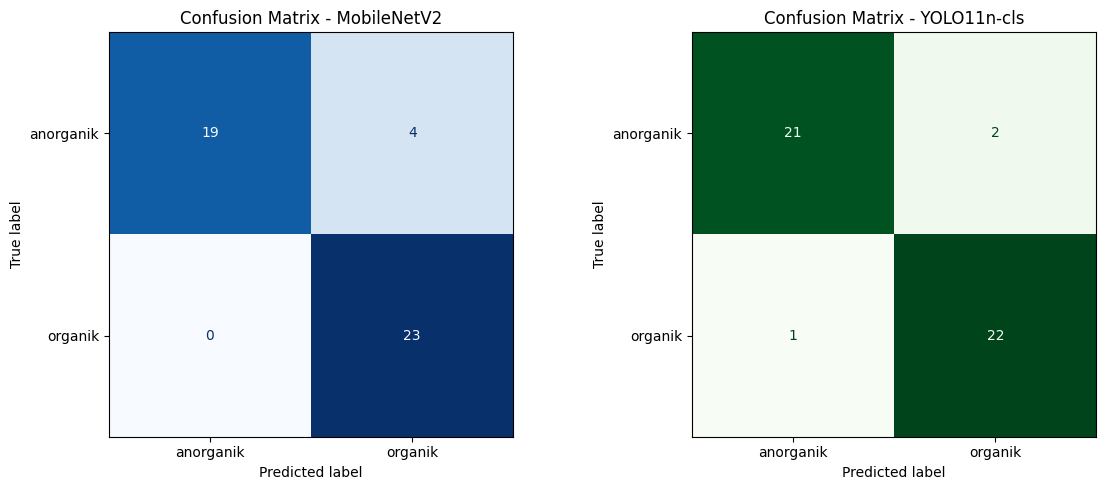

In [ ]:
def calculate_metrics(y_true, y_pred, model_name, inference_time, fps):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0
    )
    return {
        'Model': model_name,
        'Accuracy (%)': accuracy_score(y_true, y_pred) * 100,
        'Precision (%)': precision * 100,
        'Recall (%)': recall * 100,
        'F1-score (%)': f1 * 100,
        'Inference Time (seconds)': inference_time,
        'FPS': fps
    }

mobilenet_metrics = calculate_metrics(
    y_test_true, mobilenet_predictions,
    'MobileNetV2', mobilenet_inference_time, mobilenet_fps
)

yolo_metrics = calculate_metrics(
    y_test_true, yolo_predictions,
    'YOLO11n-cls', yolo_inference_time, yolo_fps
)

final_results = pd.DataFrame([mobilenet_metrics, yolo_metrics])
display(final_results.round(4))

final_results.to_csv(WORK_DIR / 'hasil_final_testing.csv', index=False)

print('\\nCLASSIFICATION REPORT - MobileNetV2')
print(classification_report(
    y_test_true, mobilenet_predictions,
    target_names=CLASS_NAMES, zero_division=0
))

print('\\nCLASSIFICATION REPORT - YOLO11n-cls')
print(classification_report(
    y_test_true, yolo_predictions,
    target_names=CLASS_NAMES, zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_true, mobilenet_predictions,
    display_labels=CLASS_NAMES, cmap='Blues',
    ax=axes[0], colorbar=False
)
axes[0].set_title('Confusion Matrix - MobileNetV2')

ConfusionMatrixDisplay.from_predictions(
    y_test_true, yolo_predictions,
    display_labels=CLASS_NAMES, cmap='Greens',
    ax=axes[1], colorbar=False
)
axes[1].set_title('Confusion Matrix - YOLO11n-cls')
plt.tight_layout()
plt.show()

## 7. Catatan penting untuk laporan skripsi

- Final testing dilakukan pada independent test set yang sama untuk kedua model.
- Data test tidak digunakan saat training, validasi, pemilihan epoch, atau Cross Validation.
- FPS dihitung sebagai jumlah gambar test dibagi total waktu prediksi. Pengukuran YOLO melalui API `predict` mencakup pipeline prediksi Ultralytics (termasuk preprocessing dan postprocessing), sedangkan MobileNet menggunakan `model.predict`; jelaskan definisi pengukuran ini secara konsisten pada Bab 3.
- Pastikan versi TensorFlow, PyTorch, Ultralytics, perangkat (CPU/GPU), dan konfigurasi batch dicatat.
- Periksa parameter augmentasi YOLO pada versi Ultralytics yang digunakan. Dukungan parameter transformasi klasifikasi dapat berubah antarversi.
- Notebook ini disiapkan sebagai template; jalankan di Colab dengan dataset dan lingkungan Anda untuk memperoleh hasil eksperimen sebenarnya.